# Image Classification using ANN (Fashion-MNIST)

This notebook builds a simple **Artificial Neural Network (ANN)** that classifies 28×28 grayscale clothing images into 10 categories.

**How to run in Google Colab:** click **Runtime → Run all**. The dataset downloads automatically, so no upload is needed. A GPU is not required.

## Step 1: Import libraries

We use NumPy for arrays, Matplotlib for plots, and TensorFlow/Keras for building the network. Colab already has these installed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)

## Step 2: Load the Fashion-MNIST dataset

The dataset has 70,000 grayscale images: 60,000 for training and 10,000 for testing. The 10 classes are listed in `class_names`.

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print("Training shape:", x_train_full.shape)
print("Test shape:    ", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training shape: (60000, 28, 28)
Test shape:     (10000, 28, 28)


## Step 3: Preprocess the images

Pixel values range from 0 to 255. Dividing by 255 scales them to 0 to 1, which helps the network train more smoothly.

In [3]:
x_train_full = x_train_full / 255.0
x_test = x_test / 255.0

## Step 4: Build the ANN

- **Flatten** turns each 28×28 image into 784 numbers.
- **Dense 128 (ReLU)** and **Dense 64 (ReLU)** are hidden layers that learn patterns.
- **Dropout (0.2)** randomly switches off 20% of neurons during training to reduce overfitting.
- **Dense 10 (Softmax)** gives one probability for each clothing class.

In [4]:
model = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## Step 5: Train the model

The model trains for 10 epochs (passes over the data) with batches of 32 images. 10% of the training data is held out as a **validation set** to monitor progress.

In [5]:
history = model.fit(x_train_full, y_train_full,
                    epochs=10, batch_size=32,
                    validation_split=0.1, verbose=1)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8056 - loss: 0.5428 - val_accuracy: 0.8478 - val_loss: 0.4163
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8502 - loss: 0.4102 - val_accuracy: 0.8520 - val_loss: 0.3976
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8625 - loss: 0.3727 - val_accuracy: 0.8593 - val_loss: 0.3997
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8713 - loss: 0.3504 - val_accuracy: 0.8840 - val_loss: 0.3347
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8754 - loss: 0.3364 - val_accuracy: 0.8790 - val_loss: 0.3278
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8811 - loss: 0.3238 - val_accuracy: 0.8702 - val_loss: 0.3456
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8837 - loss: 0.3104 - val_accuracy: 0.8820 - val_loss: 0.3393
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8893 - loss: 0.2996 -

## Step 6: Evaluate on unseen test data

The 10,000 test images were never used during training, so this gives an honest measure of accuracy.

In [6]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss:     {test_loss:.4f}")


Test Accuracy: 87.63%
Test Loss:     0.3443


## Step 7: Plot the training curves

The left plot shows accuracy and the right plot shows loss, for both training and validation data. A growing gap between the two lines is a sign of overfitting.

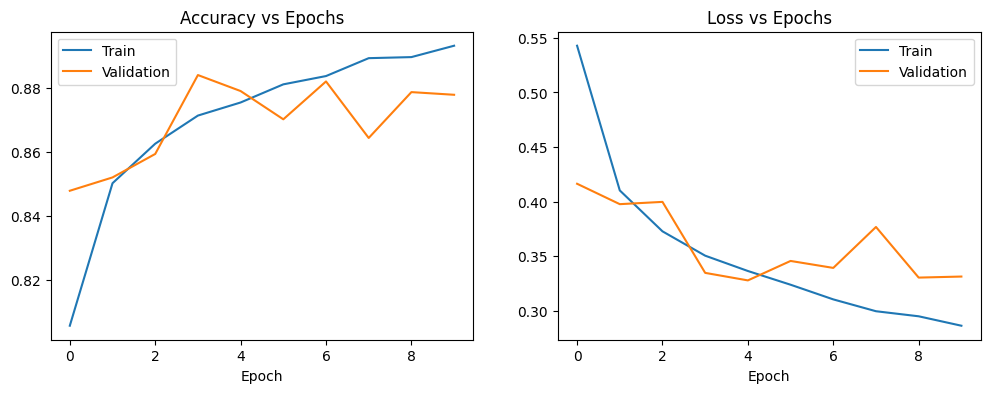

In [7]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy vs Epochs')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss vs Epochs')
plt.xlabel('Epoch')
plt.legend()

plt.show()

## Step 8: Display predictions on test images

Green titles mean the prediction is correct, and red titles mean it is wrong.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step


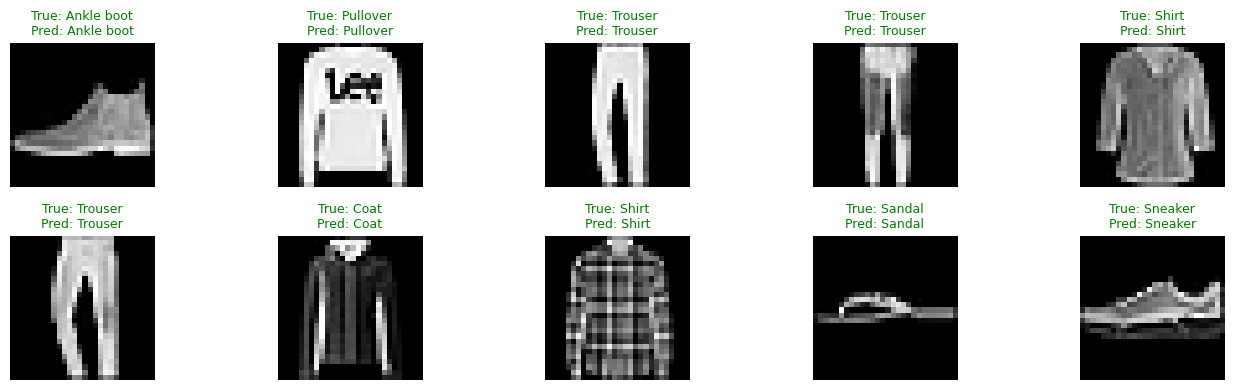

In [8]:
probs = model.predict(x_test[:10])
preds = np.argmax(probs, axis=1)

plt.figure(figsize=(14, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    color = 'green' if preds[i] == y_test[i] else 'red'
    plt.title(f"True: {class_names[y_test[i]]}\nPred: {class_names[preds[i]]}",
              color=color, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

## Step 9: Predict a single image

This function is used during the demonstration. Change the index to try other test images (0 to 9,999).

In [9]:
def predict_image(index):
    img = x_test[index]
    p = model.predict(img[np.newaxis, ...], verbose=0)[0]
    print(f"Predicted: {class_names[np.argmax(p)]} "
          f"({np.max(p)*100:.1f}% confidence)")
    print("True:      ", class_names[y_test[index]])

predict_image(5)

Predicted: Trouser (100.0% confidence)
True:       Trouser


## Step 10: Test the model on your own image

Upload a photo of a single clothing item. For best results:
- Use a plain, light or dark background with the item in the centre.
- Crop the photo so the item fills most of the frame.
- Use a clear image of one item only (T-shirt, trouser, sneaker, bag, and so on).

The model was trained on small grayscale images, so the photo is converted to grayscale, resized to 28×28 and, if needed, inverted so the item is bright on a dark background (like the training data).

**Placeholder: upload your image in the next cell.**

In [ ]:
try:
    from google.colab import files
    uploaded = files.upload()
    image_path = list(uploaded.keys())[0]
except ImportError:
    # Running locally instead of Colab: replace with the path to your image
    image_path = "your_image.jpg"

print("Using image:", image_path)

### Preprocess and predict

The same steps are used as for the training data: grayscale, 28×28 size, bright item on a dark background, and pixel values scaled to 0–1.

In [ ]:
from PIL import Image, ImageOps

def preprocess_user_image(path):
    img = Image.open(path).convert("L")
    img = ImageOps.exif_transpose(img)
    img = ImageOps.autocontrast(img)
    img = img.resize((28, 28), Image.LANCZOS)
    arr = np.array(img).astype("float32")

    # Fashion-MNIST has a dark background, so invert if the border is bright
    border = np.concatenate([arr[0], arr[-1], arr[:, 0], arr[:, -1]]).mean()
    if border > 127:
        arr = 255 - arr

    return arr / 255.0

user_img = preprocess_user_image(image_path)
probs = model.predict(user_img[np.newaxis, ...], verbose=0)[0]
pred = np.argmax(probs)

print(f"Predicted: {class_names[pred]} ({probs[pred] * 100:.1f}% confidence)")

### Show the image and the probability for each class

The bar chart shows how confident the model is for every category. The highest bar is the prediction.

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(user_img, cmap='gray')
plt.title(f"Model input (28×28)\nPredicted: {class_names[pred]}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.barh(class_names, probs * 100, color=['green' if i == pred else 'steelblue' for i in range(10)])
plt.xlabel('Confidence (%)')
plt.title('Probability for each class')
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()